In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
np.set_printoptions(legacy='1.21')

In [2]:
#QUESTION 1
#Create a NumPy array containing all multiples of 5 from 5 to 100 inclusive.

In [3]:
#Answer to Question 1
arr = np.arange(5, 101, 5)
arr

array([  5,  10,  15,  20,  25,  30,  35,  40,  45,  50,  55,  60,  65,
        70,  75,  80,  85,  90,  95, 100])

In [4]:
#QUESTION 2
#Define a Python function that calculates the present value of a 
#growing perpetuity, which provides a payment $C$ next period 
#that grows at a constant rate $g$ indefinitely, 
#discounted at rate $r$ (where $r > g$). 
#The formula is $PV = \frac{C}{r - g}$. Test your function with $C = 100$, $g = 0.02$, and $r = 0.07$.


In [5]:
#Answer to Question 2
def growing_perpetuity(C, r, g):
    if r <= g:
        return None
    return C / (r - g)
pv = growing_perpetuity(100, 0.07, 0.02)
print(pv)

2000.0


In [6]:
#QUESTION 3
#Compute the Macaulay duration of a 4-year bond paying 
#an annual coupon of \$4 in years 1, 2, and 3, and a 
#final payment of \$104 (coupon plus principal) in year 4. The yield to maturity is 6\%.

In [7]:
#Answer to Question 3
y = 0.06
cf = [4, 4, 4, 104]
pv_cf = [cf[t-1] / (1 + y)**t for t in range(1, 5)]
price = sum(pv_cf)
weights = [pv / price for pv in pv_cf]
duration = sum([t * w for t, w in zip(range(1, 5), weights)])
print(duration)


3.7657757296299637


In [8]:
#QUESTION 4
#A put option gives the owner the right to sell a stock at strike price $K = 100$. 
#The payoff at maturity $T$ is given by $\max(K - S_T, 0)$, where $S_T$ is the stock price at maturity. 
#1) Write a function \texttt{put\_payoff(S\_T, K=100)} that returns the payoff.
#2) Simulate 15,000 values of $S_T$ assuming $S_T$ follows a normal distribution 
#with mean 102 and standard deviation 12.
#3) Compute the expected payoff of the put option and its standard deviation.

In [9]:
#Answer to Question 4
def put_payoff(S_T, K=100):
    return max(K - S_T, 0)

S_T = np.random.normal(102, 12, 15000)
payoffs = [put_payoff(s, 100) for s in S_T]

mean_payoff = np.mean(payoffs)
std_payoff = np.std(payoffs)
print(mean_payoff, std_payoff)

3.8004756151525156 6.250856372436307


In [10]:
#QUESTION 5
#Plot a histogram with 35 bins displaying the distribution of the simulated 
#put option payoffs from Question 4. Set the edge color to black, 
#label the axes appropriately, and add a title.

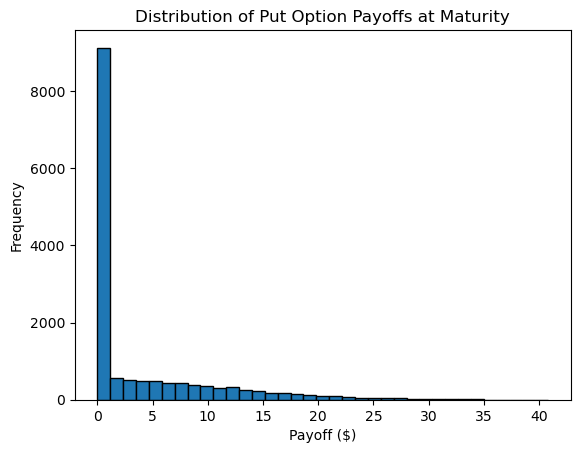

In [11]:
#Answer to Question 5
import matplotlib.pyplot as plt

plt.hist(payoffs, bins=35, edgecolor='black')
plt.title('Distribution of Put Option Payoffs at Maturity')
plt.xlabel('Payoff ($)')
plt.ylabel('Frequency')
plt.show()


In [12]:
#QUESTION 6
#The file TechStocks.csv contains daily closing prices for Apple and Microsoft 
#in columns named AAPL and MSFT, from the first trading day in 2026 to October 14 2026. 
#Write Python code to:
#1) Load the dataset into a DataFrame.
#2) Calculate the daily log returns for both assets ($r_t = \ln(P_t / P_{t-1})$).
#3) Plot both series of daily log returns on a single line chart over time.

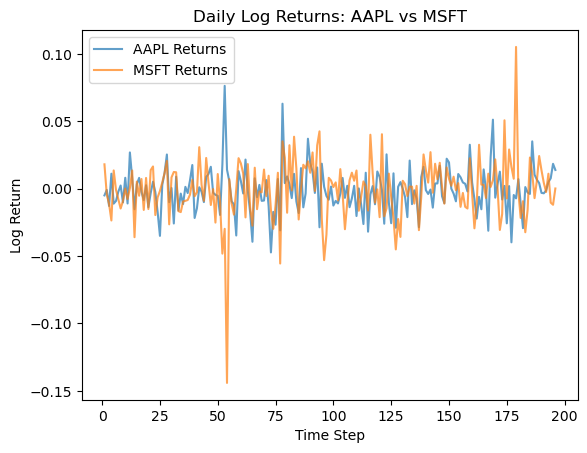

In [13]:
#Answer to Question 6
df = pd.read_csv("TechStocks.csv")
df['AAPL_ret'] = np.log(df['AAPL'] / df['AAPL'].shift(1))
df['MSFT_ret'] = np.log(df['MSFT'] / df['MSFT'].shift(1))

plt.plot(df['AAPL_ret'], label='AAPL Returns', alpha=0.7)
plt.plot(df['MSFT_ret'], label='MSFT Returns', alpha=0.7)
plt.title('Daily Log Returns: AAPL vs MSFT')
plt.xlabel('Time Step')
plt.ylabel('Log Return')
plt.legend()
plt.show()